In [1]:
import requests
import pprint
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray as rxr
from pystac_client import Client
from shapely.geometry import shape

In [2]:
cities_url = 'https://api.pdok.nl/kadaster/brk-bestuurlijke-gebieden/ogc/v1/collections/gemeentegebied/items?f=json'
n_hoods_url = 'https://api.pdok.nl/cbs/wijken-en-buurten-2026/ogc/v1/collections/buurten/items?f=json'

pdok_crs = 'EPSG:4326'
proj_crs = 'EPSG:28992'

selected_columns = ['naam', 'bu_naam', 'geometry']
renamed_columns = {'naam': 'name', 'bu_naam': 'n_hood_name'}
filter_column = 'name'

input_list = ['zwolle', 'almelo', 'ommen']

bands = ['nir', 'red']
client_url = "https://earth-search.aws.element84.com/v1"
collections=['sentinel-2-c1-l2a']
date_range='2026-01-01/2026-10-31'
query=['eo:cloud_cover<10']

In [3]:
def download_gdf(url, crs):

    print(f'Downloading from {url}')
    
    features = []
    
    while url:
    
        req = requests.get(url)
        req.raise_for_status()
        
        res = req.json()
    
        feature = res['features']
        features.extend(feature)
        
        url = next((
            link['href']
            for link in res['links']
            if link['rel']=='next'
        ), None)
    
    print(f'Download complete: {len(features)} features retrieved')
    
    return gpd.GeoDataFrame.from_features(features, crs=crs)

def clean_gdf(gdf, selected_columns, renamed_columns, crs):

    cleaned_gdf = (
        gdf.select(pd.Index(selected_columns).intersection(gdf.columns))
        .rename(columns=renamed_columns)
        .pipe(lambda geodf: geodf.set_geometry(geodf.geometry.make_valid()))
        .to_crs(crs)
    )

    print(f'CRS transformed to: {cleaned_gdf.crs}')
    print(f'Final columns: {cleaned_gdf.columns.tolist()}')

    return cleaned_gdf

def build_gdfs(input_list, boundary_gdf, polygon_gdf, filter_column):
    
    output_dict = {}

    points = polygon_gdf.set_geometry(
        polygon_gdf.geometry.representative_point()
    )
    
    for name in input_list:
    
        boundary = boundary_gdf.loc[
            boundary_gdf[filter_column].str.casefold() == name.casefold()
        ]

        matches = gpd.sjoin(
            points,
            boundary,
            predicate='within'
        )

        output_dict[name] = polygon_gdf.loc[matches.index.unique()]

    return output_dict

In [4]:
cities = clean_gdf(
    download_gdf(cities_url, pdok_crs),
    selected_columns,
    renamed_columns,
    proj_crs
)

Download complete: 342 features retrieved
CRS transformed to: EPSG:28992
Final columns: ['name', 'geometry']


In [5]:
n_hoods = clean_gdf(
    download_gdf(n_hoods_url, pdok_crs),
    selected_columns,
    renamed_columns,
    proj_crs
)

Download complete: 14914 features retrieved
CRS transformed to: EPSG:28992
Final columns: ['n_hood_name', 'geometry']


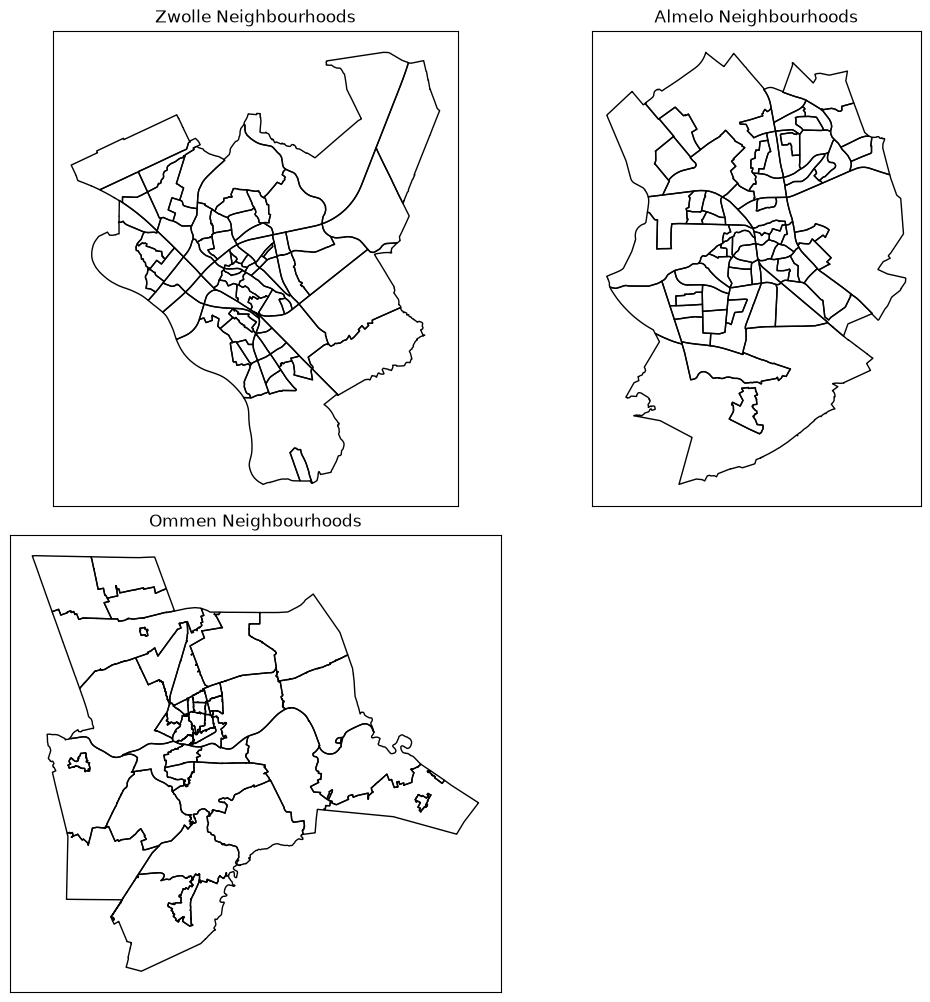

In [6]:
n_hoods_by_city = build_gdfs(
    input_list,
    cities,
    n_hoods,
    'name'
)

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(10,10),
    constrained_layout=True
)

axes = axes.flatten()

for ax, (name, gdf) in zip(axes, n_hoods_by_city.items()):

    gdf.plot(
        ax=ax,
        color='none'
    )

    ax.set(
        title=f'{name.title()} Neighbourhoods',
        xlabel='',
        ylabel='',
        xticks=[],
        yticks=[]
    )

for ax in axes[len(n_hoods_by_city): ]:
    ax.remove()

plt.show()    

In [8]:
def get_ndvi(
    aoi,
    bands,
    client_url,
    collections,
    date_range,
    query
):
        
    combined_gdf = (
        pd.concat(
            aoi.values(),
            ignore_index=True
        )
        .to_crs('EPSG:4326')
    )
    
    combined_gdf_geom = combined_gdf.geometry.union_all()
        
    client = Client.open(client_url)
    
    search = client.search(
        collections=collections,
        bbox=combined_gdf.total_bounds,
        datetime=date_range,
        query=query
    )
    
    item = next(
        (
            item
            for item in search.items()
            if shape(item.geometry).covers(combined_gdf_geom)
        ),
        None
    )

    band_arrays = {
        band: (
            rxr.open_rasterio(
                item.assets[band].href,
                masked=True
            )
            .squeeze(dim='band')
        )
        for band in bands
    }

    ndvi_dict = {}
    
    for name, gdf in aoi.items():
        
        boundary = gdf.to_crs('EPSG:4326').dissolve()
    
        clipped_arrays = {
            band: (
                array.rio.clip(
                    [boundary.geometry.iloc[0]],
                    crs=boundary.crs
                    
                )
            )
            for band, array in band_arrays.items()
        }
        
        ndvi = (
            ( clipped_arrays['nir'] - clipped_arrays['red'] ) /
            ( clipped_arrays['nir'] + clipped_arrays['red'] )
        )
        
        ndvi_dict[name] = ndvi

    return ndvi_dict

ndvi_dictt = get_ndvi(
    n_hoods_by_city,
    bands,
    client_url,
    collections,
    date_range,
    query
)

In [ ]:
def get_ndvi(
    aoi,
    bands,
    client_url,
    collections,
    date_range,
    query
):
        
    combined_gdf = (
        pd.concat(
            aoi.values(),
            ignore_index=True
        )
        .to_crs('EPSG:4326')
    )
    
    combined_gdf_geom = combined_gdf.geometry.union_all()
        
    client = Client.open(client_url)
    
    search = client.search(
        collections=collections,
        bbox=combined_gdf.total_bounds,
        datetime=date_range,
        query=query
    )
    
    item = next(
        (
            item
            for item in search.items()
            if shape(item.geometry).covers(combined_gdf_geom)
        ),
        None
    )

    band_arrays = {
        band: (
            rxr.open_rasterio(
                item.assets[band].href,
                masked=True
            )
            .squeeze(dim='band')
        )
        for band in bands
    }

    ndvi_dict = {}
    
    for name, gdf in aoi.items():
        
        boundary = gdf.to_crs('EPSG:4326').dissolve()
    
        clipped_arrays = {
            band: (
                array.rio.clip(
                    [boundary.geometry.iloc[0]],
                    crs=boundary.crs
                    
                )
            )
            for band, array in band_arrays.items()
        }
        
        ndvi = (
            ( clipped_arrays['nir'] - clipped_arrays['red'] ) /
            ( clipped_arrays['nir'] + clipped_arrays['red'] )
        )

        ndvi_list = []
        
        for row in gdf.itertuples():
            
            ndvi_clipped = ndvi.rio.clip(
                [row.geometry.iloc[0]],
                crs=gdf.crs
            )

            mean_ndvi = ndvi_clipped.mean()

            ndvi_list.append(mean_ndvi)

        gdf['mean_ndvi'] = ndvi_list

In [10]:
zwolle = ndvi_dictt['zwolle']

In [ ]:
z = n_hoods_by_city['zwolle'].copy()

z['mean_ndvi'] = ndvi